# <font color="orange"> Análisis de los datos a la universidad </font>

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
import numpy as np

### Apartado 1.1


In [3]:
cols = ['des_universidad', 'curso_academico', 'cod_titulacion', 'des_titulacion',
        'des_forma_admision', 'nota_admision', 'ind_se_matricula_en_primero', 'ind_accede_al_SUE_por_1a_vez']

df_uam = pd.read_csv('uam2425.csv', usecols=cols, decimal=",")
df_ucm = pd.read_csv('ucm2425.csv', usecols=cols, decimal=",")
df_ujrc = pd.read_csv('urjc2425.csv', usecols=cols, decimal=",")

df_uni = [df_uam, df_ucm, df_ujrc]

for uni in df_uni:
    for column in uni:
        uni.dropna(how='all', axis=1, inplace=True)
        


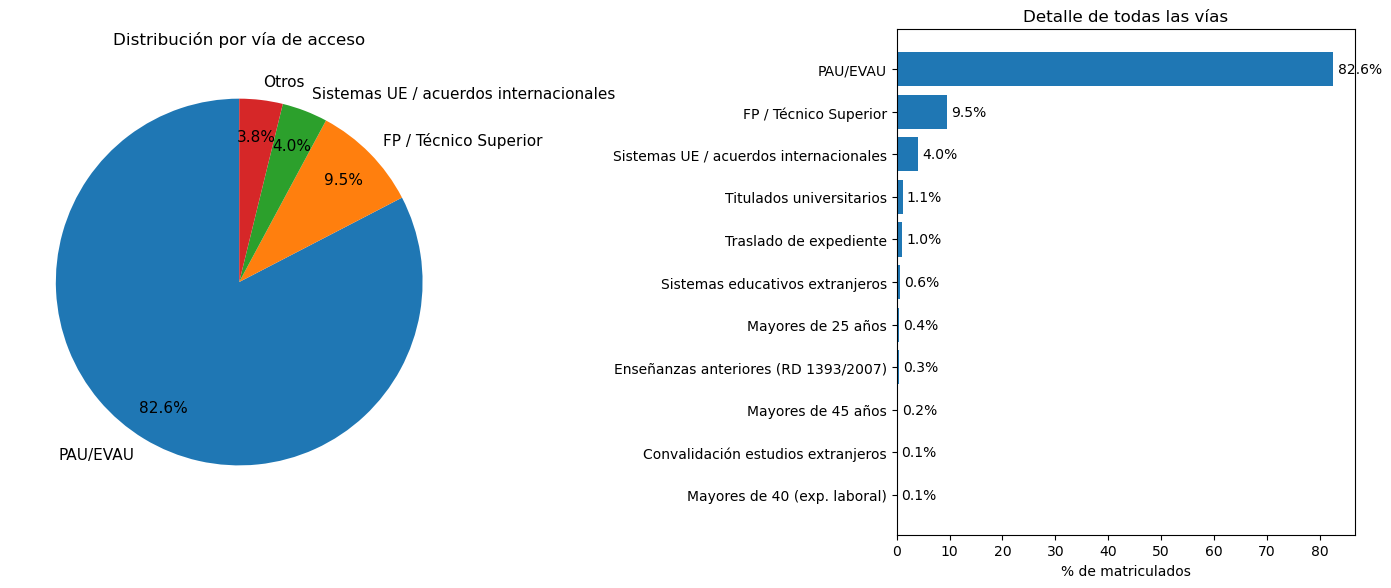

In [4]:
nombre = 'des_forma_admision'

nombres_cortos = {
	'Pruebas de Acceso': 'PAU/EVAU',
	'Técnica/o Superior': 'FP / Técnico Superior',
	'otro título universitario': 'Titulados universitarios',
	'sistemas miembros de la Unión Europea': 'Sistemas UE / acuerdos internacionales',
	'enseñanzas anteriores': 'Enseñanzas anteriores (RD 1393/2007)',
	'Mayores de 25': 'Mayores de 25 años',
	'Mayores de 45': 'Mayores de 45 años',
	'Mayores de 40': 'Mayores de 40 (exp. laboral)',
	'traslado de Expediente': 'Traslado de expediente',
	'homologación': 'Sistemas educativos extranjeros',
	'Convalidación parcial': 'Convalidación estudios extranjeros',
}

def renombrar(via):
	for clave, corto in nombres_cortos.items():
		if clave in via:
			return corto
	return via

total = pd.concat([
	df_uam[nombre],
	df_ucm[nombre],
	df_ujrc[nombre]
]).map(renombrar).value_counts()

pct = total / total.sum() * 100

# Pie: vías >= 2 % + "Otros"
pie_data = pct[pct >= 2].copy()
pie_data['Otros'] = pct[pct < 2].sum()

fig, (ax_pie, ax_bar) = plt.subplots(1, 2, figsize=(14, 6))

ax_pie.pie(pie_data.values, labels=pie_data.index,
           autopct='%1.1f%%', startangle=90, pctdistance=0.8,
           textprops={'fontsize': 11})
ax_pie.set_title('Distribución por vía de acceso')

barras = pct.sort_values()
bars = ax_bar.barh(barras.index, barras.values)
ax_bar.bar_label(bars, fmt='%.1f%%', padding=3)
ax_bar.set_xlabel('% de matriculados')
ax_bar.set_title('Detalle de todas las vías')

fig.tight_layout()

#### Justificación del diseño

- **Tipo de gráfico:** combinamos un diagrama circular y un diagrama de barras horizontales. El circular sirve para ver de un vistazo qué parte del total representa cada vía (son porcentajes que suman 100 %). Las barras permiten comparar con precisión todas las vías, incluidas las muy minoritarias, que en el circular serían porciones imposibles de distinguir.
- **Agrupación "Otros":** en el circular, las vías por debajo del 2 % se agrupan en "Otros" para que no se solapen las etiquetas. En las barras se muestran todas, así no se pierde información.

- **Leyenda:** No incluimos leyenda pues es suficentemente legible una vez acortados los nombres.

### <span style="color: blue;">¿Qué vía de acceso agrupa a la mayor proporción de matriculados?</span>

Las Pruebas de Acceso a la Universidad (EVAU, PAU y pruebas anteriores), con un 82,6 % de los 33.428 matriculados de las tres universidades. Esto supone más de 4 de cada 5 estudiantes, muy por encima de todas las demás vías juntas (17,4 %).

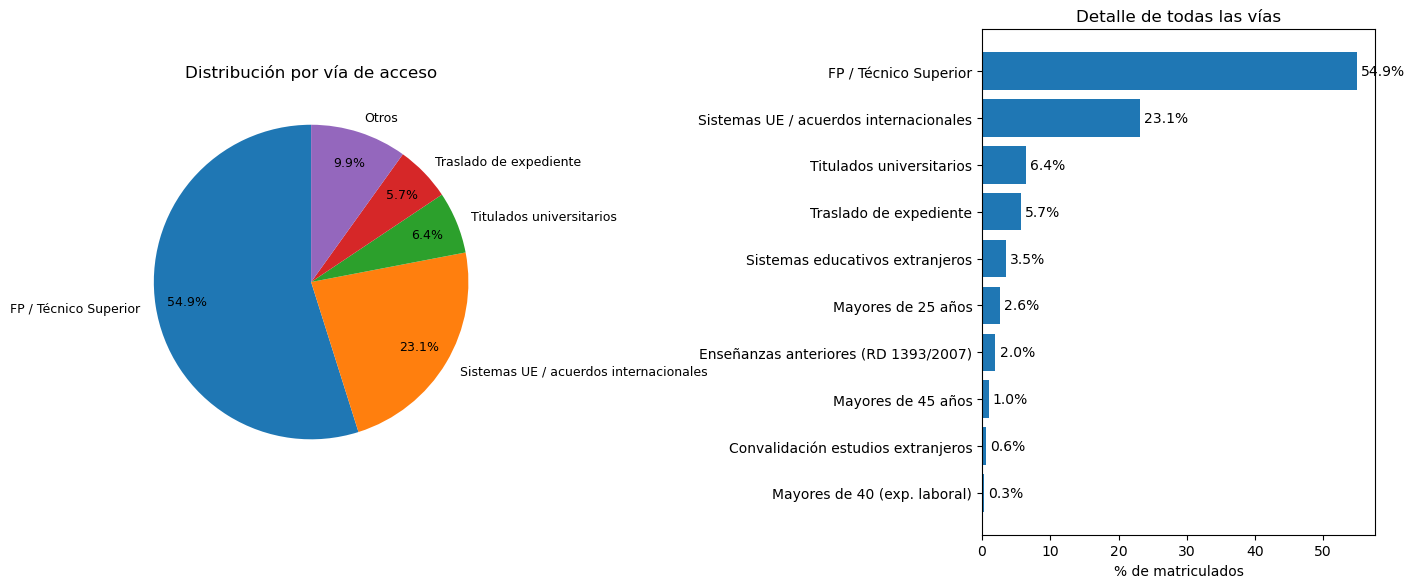

In [5]:
total2 = total.iloc[1:]

pct = total2 / total2.sum() * 100

# Pie: vías >= 2 % + "Otros"
pie_data = pct[pct >= 4].copy()
pie_data['Otros'] = pct[pct < 4].sum()

fig, (ax_pie, ax_bar) = plt.subplots(1, 2, figsize=(14, 6))

ax_pie.pie(pie_data.values, labels=pie_data.index,
           autopct='%1.1f%%', startangle=90, pctdistance=0.8,
           textprops={'fontsize': 9})
ax_pie.set_title('Distribución por vía de acceso')

barras = pct.sort_values()
bars = ax_bar.barh(barras.index, barras.values)
ax_bar.bar_label(bars, fmt='%.1f%%', padding=3)
ax_bar.set_xlabel('% de matriculados')
ax_bar.set_title('Detalle de todas las vías')

fig.tight_layout()


#### Justificación del diseño

Repetimos la misma combinación de circular y barras, pero recalculando los porcentajes sobre el total de estudiantes que no entran por PAU/EVAU. El umbral de "Otros" del circular sube al 4 % porque, al quitar la vía principal, hay más categorías pequeñas que antes compartían el mismo espacio.

### <span style="color: blue;">Si excluyes esa vía principal, ¿qué otro cupo destaca sobre los demás? ¿Tuviste que tomar alguna decisión de diseño en tu gráfico para poder visualizar y comparar correctamente estos cupos minoritarios?</span>

Destaca el acceso por títulos de Técnico Superior (FP, Enseñanzas Artísticas y Deportivas): supone un 9,5 % del total, y casi 55 % de los accesos que no son por PAU/EVAU. Le siguen, a bastante distancia, los estudiantes de sistemas de la UE o con acuerdos internacionales (4,0 % del total, 23 % de los no-PAU). El resto de cupos (titulados, traslados, mayores de 25/40/45, homologaciones…) no llegan al 1,2 % cada uno. Notese que aplicamos un umbral que agrupa los cupos de menor representación que 2%.


### Apartado 1.2

In [6]:
#

rama = pd.read_excel('rama-campo.xlsx', sheet_name='Titulación_Rama', header=5, usecols=[4, 8])  

rama.columns=['cod_titulacion', 'rama']
rama['cod_titulacion'] = pd.to_numeric(rama['cod_titulacion'], errors='coerce')
rama = rama.dropna().drop_duplicates('cod_titulacion')
rama['cod_titulacion'] = rama['cod_titulacion'].astype('int64')

def cargar(fichero):
    df = pd.read_csv(fichero, usecols=cols, decimal=',')
    df['cod_titulacion'] = df['cod_titulacion'].astype('Int64')
    return df.merge(rama, on='cod_titulacion', how='left')

df_uam  = cargar('uam2425.csv')
df_ucm  = cargar('ucm2425.csv')
df_ujrc = cargar('urjc2425.csv')

df_total = pd.concat([df_uam, df_ucm, df_ujrc])
df_total.dropna(subset=['rama'])
acceso = {}
for r, grupo in df_total.groupby('rama'):
    si = (grupo['ind_se_matricula_en_primero'] == 'SÍ').sum()
    no = (grupo['ind_se_matricula_en_primero'] == 'NO').sum()
    nota_media= np.mean(grupo['nota_admision'])
    acceso[r] = {'SÍ': si, 'NO': no, 'ratio': si / (si + no), 'media':nota_media}
acceso['nota_max']={'media':14.0}


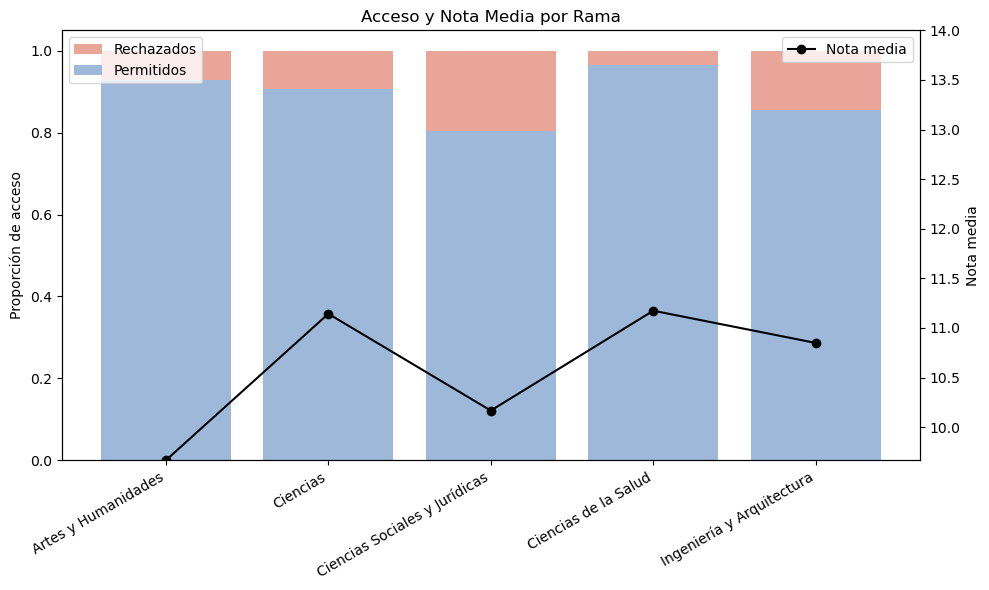

In [7]:
import pandas as pd
import matplotlib.pyplot as plt


df_plot = pd.DataFrame.from_dict(acceso, orient='index').drop('nota_max', errors='ignore')
plt.figure(figsize=(10, 6))
plt.bar(df_plot.index, 1 - df_plot['ratio'], bottom=df_plot['ratio'], color='#E8A598', label='Rechazados')
plt.bar(df_plot.index, df_plot['ratio'], color='#9DB8D9', label='Permitidos')
plt.ylabel('Proporción de acceso')
plt.xticks(rotation=30, ha='right')
plt.legend(loc='upper left')

plt.twinx()
plt.plot(df_plot.index, df_plot['media'], color='black', marker='o', label='Nota media', )
plt.ylim(df_plot['media'].min(), 14)
plt.ylabel('Nota media')
plt.legend(loc='upper right')

plt.title("Acceso y Nota Media por Rama")
plt.tight_layout()
plt.show()

#### Justificación del diseño

- **Tipo de gráfico:** Elegimos un diagrama de barras, una barra por rama de estudio, que representa la proporción de acceso. En la propia barra podemos ver de un viztazo dicha proporción, en azul la tasa de acceso y en rojo la de rechazo, y su combinación ocupa la totalidad del rango de la barra, es decir el 100% de las solicitudes por rama. Por otra parte añadimos los puntos de la nota media en un rango del 10 al 14 para mejorar la interpretación, unidos por una linea

### <span style="color:blue;"> Comparación con informe Rtve</span>

**Fuente:** [*Las 100 carreras más demandadas y en qué universidad pública se estudian*](https://www.rtve.es/noticias/20250517/100-carreras-mas-demandadas-universidad-publica-se-estudian/16559324.shtml) (DatosRTVE, 17/05/2025), curso 2024-2025, el mismo que analizamos.

**Qué cuenta la noticia.** RTVE recopila la nota de corte más alta de cada universidad pública española y construye un ranking de las 100 titulaciones con mayor exigencia.

**Contraste con nuestros datos.** Los resultados coinciden en lo esencial:
- Las ramas con mayor nota media de acceso por nota son Ciencias de la Salud (≈11,2) y Ciencias (≈11,2), seguidas de Ingeniería y Arquitectura (≈10,9). Esto encaja con un ranking dominado por Medicina, Matemáticas y Física.
- Si bajamos al nivel de titulación, las notas medias más altas de nuestras tres universidades son el Doble Grado en Matemáticas-Física de la UCM (≈13,7) y el de Ingeniería Informática-Matemáticas (≈13,3), seguidos de Medicina en la UAM y la UCM (≈13,1). Es el mismo patrón que describe RTVE.

**Qué aporta nuestra gráfica frente a la noticia.**
1. **Mide algo distinto y complementario.** RTVE usa la nota de corte, que es la nota del último admitido, y solo la de la titulación más exigente de cada universidad. Nosotros mostramos la nota media de todos los admitidos por nota, que describe al estudiante típico de cada rama y no solo la nota de corte.
2. **Cambia la escala de análisis.** La noticia es una lista de titulaciones sueltas, mientras que nuestra figura agrega por rama de conocimiento. Así se ve una tendencia general que el ranking no muestra: ninguna titulación de Ciencias Sociales y Jurídicas destaca individualmente, y sin embargo es la rama que concentra con diferencia más estudiantes (≈56 % de los accesos).
3. **Añade el volumen y la tasa de acceso.** Un ranking de notas no dice cuántos estudiantes hay detrás ni cuántos acaban matriculándose. Nuestra figura combina en el mismo gráfico la exigencia (nota media) y la tasa de acceso. Por ejemplo, Ciencias de la Salud es a la vez la rama más exigente y la de mayor tasa de matriculación (≈97 %): quien consigue plaza en ella casi siempre la ocupa. En cambio, Ciencias Sociales y Jurídicas tiene la tasa más baja (≈80 %).
4. **Matiza el término "más demandadas".** La noticia usa "demandadas" como sinónimo de "nota de corte más alta", pero una nota de corte alta suele reflejar pocas plazas tanto como mucha demanda. Nuestros datos muestran que las titulaciones con más nota (dobles grados con 13-35 admitidos) son de las que menos estudiantes reciben.




### Apartado 3.1

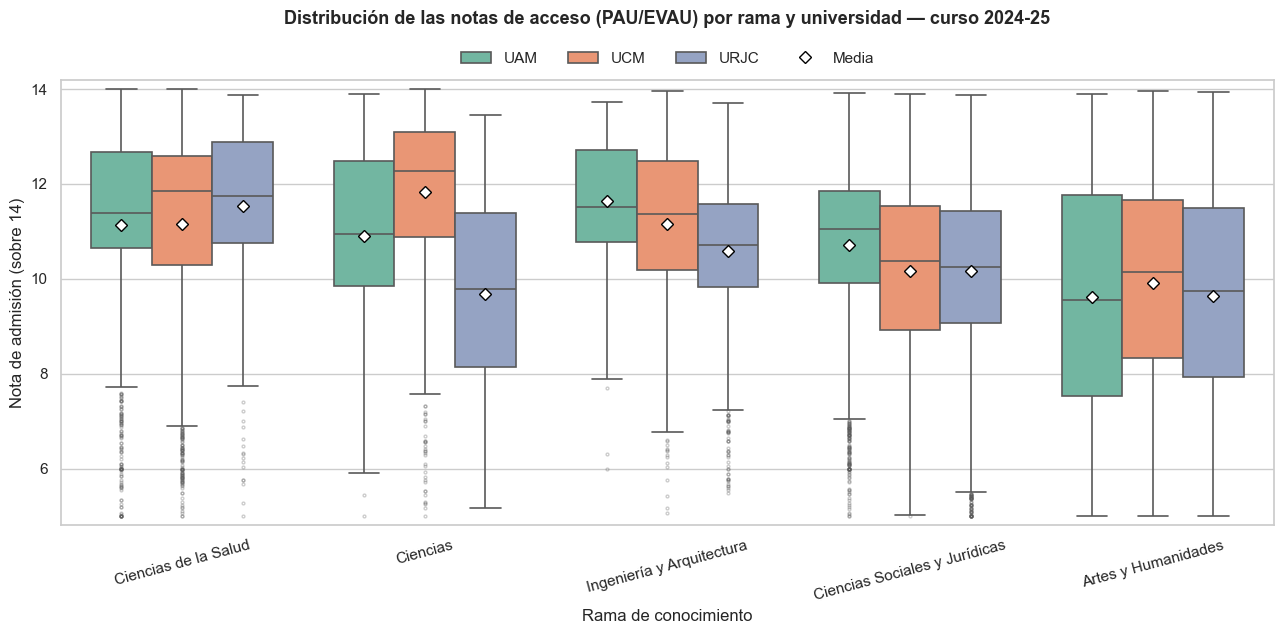

In [9]:
# Solo accesos por nota (PAU/EVAU), con rama conocida y nota válida
notas = df_total[
    df_total['des_forma_admision'].str.contains('Pruebas de Acceso', na=False)
].dropna(subset=['rama', 'nota_admision']).copy()

siglas = {
    'Universidad Autónoma de Madrid': 'UAM',
    'Universidad Complutense de Madrid': 'UCM',
    'Universidad Rey Juan Carlos': 'URJC',
}
notas['universidad'] = notas['des_universidad'].map(siglas)

# Ramas ordenadas por mediana global (de más a menos exigente)
orden_ramas = notas.groupby('rama')['nota_admision'].median().sort_values(ascending=False).index
orden_unis = ['UAM', 'UCM', 'URJC']

sb.set_theme(style='whitegrid')
fig, ax = plt.subplots(figsize=(13, 6.5))

sb.boxplot(
    data=notas, x='rama', y='nota_admision', hue='universidad',
    order=orden_ramas, hue_order=orden_unis, palette='Set2',
    showmeans=True,
    meanprops={'marker': 'D', 'markerfacecolor': 'white',
               'markeredgecolor': 'black', 'markersize': 6},
    flierprops={'marker': 'o', 'markersize': 2, 'alpha': 0.3},
    width=0.75, linewidth=1.2, ax=ax,
)

ax.set_ylim(4.8, 14.2)
ax.set_xlabel('Rama de conocimiento')
ax.set_ylabel('Nota de admisión (sobre 14)')
ax.set_title('Distribución de las notas de acceso (PAU/EVAU) por rama y universidad — curso 2024-25',
             fontsize=13, fontweight='bold', pad=40)
ax.tick_params(axis='x', rotation=15)

# Leyenda única sobre el gráfico: universidades + marcador de la media
handles, labels = ax.get_legend_handles_labels()
handles.append(plt.Line2D([], [], marker='D', linestyle='', markerfacecolor='white',
                          markeredgecolor='black', label='Media'))
ax.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, 1.0),
          ncol=4, frameon=False)

fig.tight_layout()
plt.show()


### Apartado 2.1

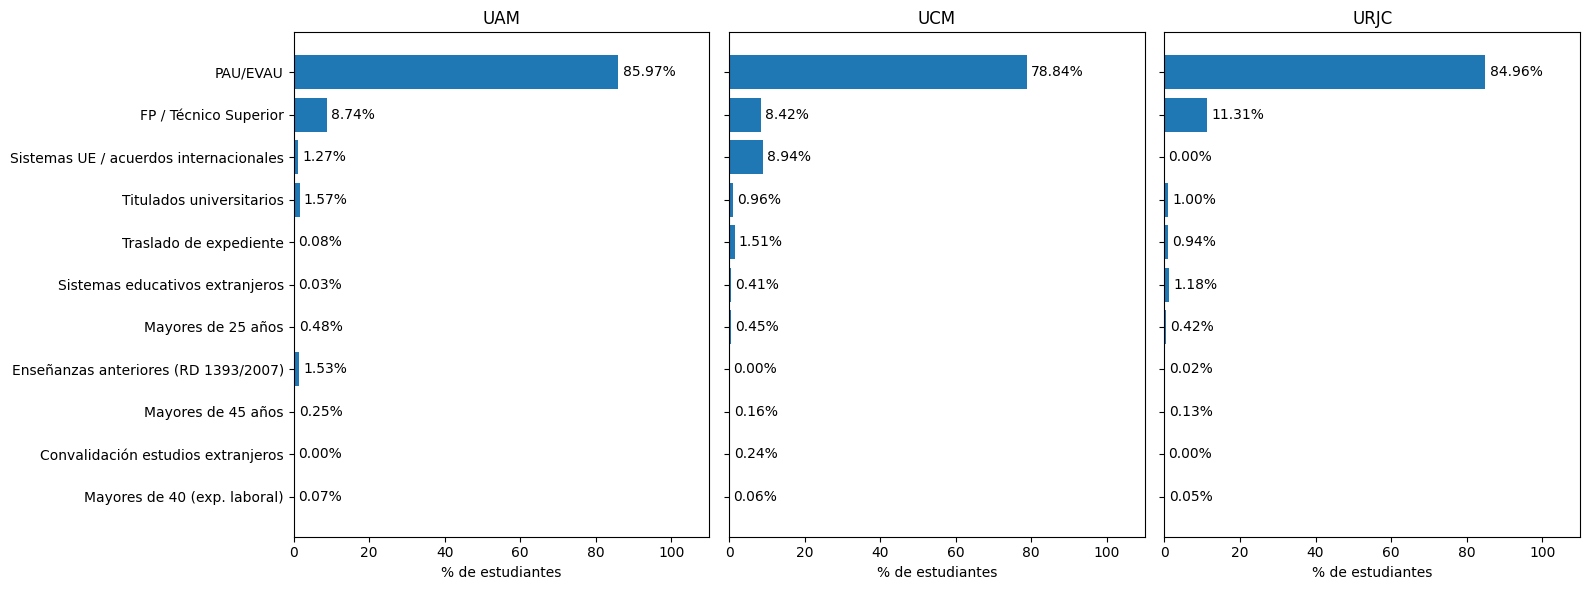

In [ ]:
universidades = {'UAM': df_uam, 'UCM': df_ucm, 'URJC': df_ujrc}

# % de cada vía dentro de cada universidad, en el mismo orden que en la Parte 1
pct_uni = pd.DataFrame({
    uni: df[nombre].map(renombrar).value_counts(normalize=True) * 100
    for uni, df in universidades.items()
}).fillna(0).loc[total.index[::-1]]

fig_2_1, axes = plt.subplots(1, 3, figsize=(16, 6), sharey=True, sharex=True)

for ax, uni in zip(axes, pct_uni.columns):
    bars = ax.barh(pct_uni.index, pct_uni[uni])
    ax.bar_label(bars, fmt='%.2f%%', padding=3)
    ax.set_xlim(0, 110)
    ax.set_xlabel('% de estudiantes')
    ax.set_title(uni)

fig_2_1.tight_layout()

In [ ]:
# Universidad con mayor porcentaje en cada vía
pct_uni.idxmax(axis=1)

des_forma_admision
Mayores de 40 (exp. laboral)               UAM
Convalidación estudios extranjeros         UCM
Mayores de 45 años                         UAM
Enseñanzas anteriores (RD 1393/2007)       UAM
Mayores de 25 años                         UAM
Sistemas educativos extranjeros           URJC
Traslado de expediente                     UCM
Titulados universitarios                   UAM
Sistemas UE / acuerdos internacionales     UCM
FP / Técnico Superior                     URJC
PAU/EVAU                                   UAM
dtype: object

#### Justificación del diseño

- **Tipo de gráfico:** usamos las mismas barras horizontales que en la Parte 1, un subplot por universidad. Descartamos el circular porque con tres circulares no se pueden comparar las porciones entre universidades.
- **Disposición:** los tres subplots en una fila, para que cada vía quede a la misma altura en las tres universidades y se pueda comparar leyendo de izquierda a derecha.
- **Ejes compartidos:** con `sharey` los nombres de las vías solo aparecen una vez, y con `sharex` la misma longitud de barra significa el mismo porcentaje en las tres universidades.
- **Etiquetas:** las vías minoritarias son barras casi invisibles al lado de PAU/EVAU, así que añadimos el valor exacto de cada barra para poder compararlas.
- **Leyenda:** no la incluimos, el título de cada subplot ya indica la universidad.

### <span style="color: blue;">Por cada una de las vías de acceso, ¿cuál es la universidad que tiene el mayor porcentaje de acceso?</span>

- **UAM:** PAU/EVAU (85,97 %, muy cerca de la URJC con 84,96 %), titulados universitarios (1,57 %), mayores de 25 años (0,48 %), enseñanzas anteriores al RD 1393/2007 (1,53 %), mayores de 45 años (0,25 %) y mayores de 40 años (0,07 %).
- **UCM:** sistemas UE / acuerdos internacionales (8,94 %, en la URJC no hay ninguno), traslado de expediente (1,51 %) y convalidación de estudios extranjeros (0,24 %, la única universidad con esta vía).
- **URJC:** FP / Técnico Superior (11,31 %) y sistemas educativos extranjeros (1,18 %).

En las vías de mayores de 25, 40 y 45 años las diferencias entre universidades son de centésimas, así que no son relevantes.

### Apartado 2.2

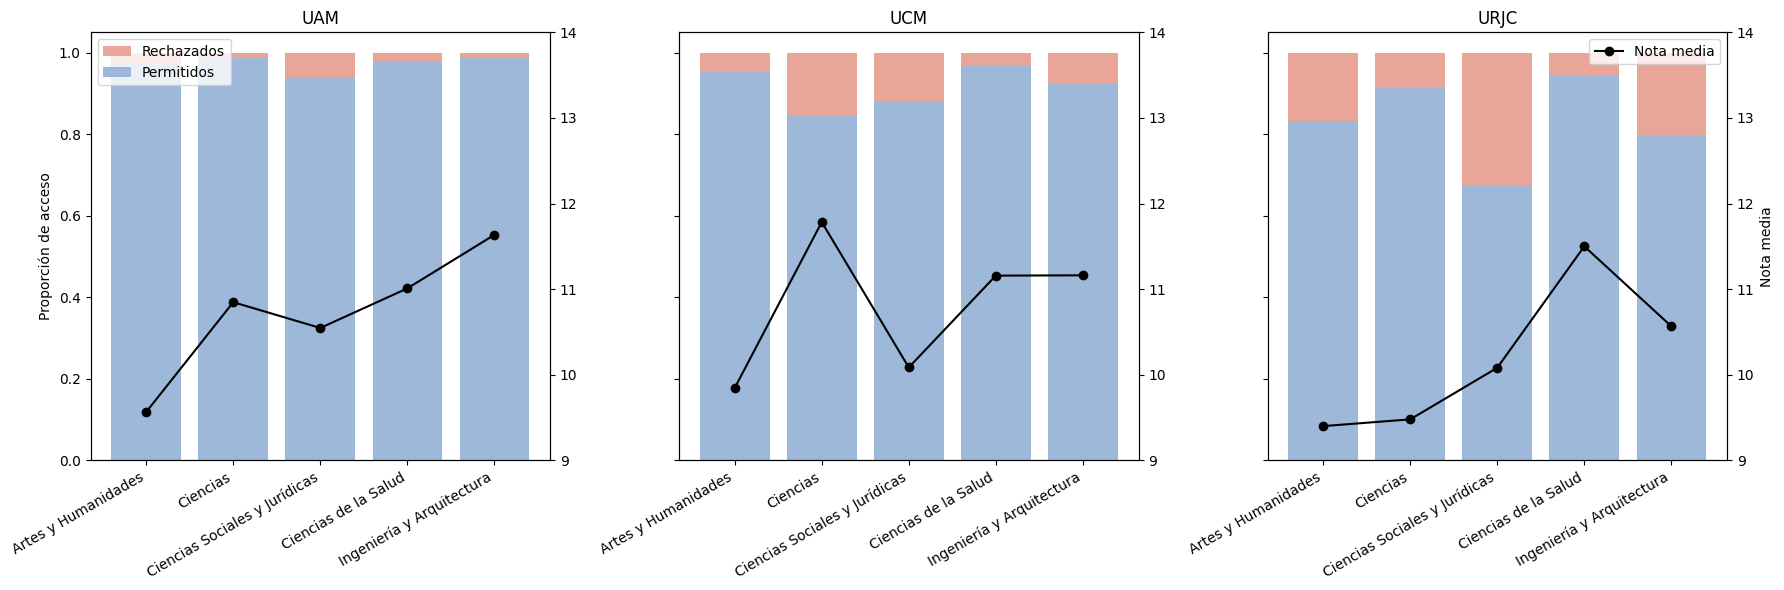

In [ ]:
fig_2_2, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
resumen = {}

for ax, (uni, df) in zip(axes, universidades.items()):
    df = df.dropna(subset=['rama'])
    ratio = df.groupby('rama')['ind_se_matricula_en_primero'].apply(lambda s: (s == 'SÍ').mean())
    media = df.dropna(subset=['nota_admision']).groupby('rama')['nota_admision'].mean()  # solo accesos por nota
    resumen[uni] = pd.DataFrame({'ratio': ratio, 'media': media})

    ax.bar(ratio.index, 1 - ratio, bottom=ratio, color='#E8A598', label='Rechazados')
    ax.bar(ratio.index, ratio, color='#9DB8D9', label='Permitidos')
    ax.set_xticks(ratio.index, ratio.index, rotation=30, ha='right')
    ax.set_title(uni)

    ax2 = ax.twinx()
    ax2.plot(media.index, media, color='black', marker='o', label='Nota media')
    ax2.set_ylim(9, 14)

axes[0].set_ylabel('Proporción de acceso')
ax2.set_ylabel('Nota media')
axes[0].legend(loc='upper left')
ax2.legend(loc='upper right')

fig_2_2.tight_layout()

In [ ]:
# Rama con mayor tasa de acceso y rama con mayor nota media por universidad
pd.concat(resumen).round(3)

ratio   media
     rama                                        
UAM  Artes y Humanidades            0.972   9.565
     Ciencias                       0.986  10.847
     Ciencias Sociales y Jurídicas  0.942  10.546
     Ciencias de la Salud           0.977  11.008
     Ingeniería y Arquitectura      0.988  11.634
UCM  Artes y Humanidades            0.954   9.846
     Ciencias                       0.847  11.783
     Ciencias Sociales y Jurídicas  0.882  10.085
     Ciencias de la Salud           0.969  11.157
     Ingeniería y Arquitectura      0.926  11.161
URJC Artes y Humanidades            0.833   9.399
     Ciencias                       0.914   9.478
     Ciencias Sociales y Jurídicas  0.674  10.081
     Ciencias de la Salud           0.942  11.500
     Ingeniería y Arquitectura      0.798  10.566

#### Justificación del diseño

- **Tipo de gráfico:** repetimos la figura de la Parte 1 (barras apiladas de permitidos y rechazados, y la nota media en un segundo eje), ahora con un subplot por universidad.
- **Disposición:** los tres subplots en una fila y las ramas en el mismo orden, para comparar la misma rama entre universidades.
- **Ejes compartidos:** la proporción de acceso comparte eje (`sharey`) y el eje de la nota tiene el mismo rango (9 a 14) en los tres subplots, para que una línea más alta signifique siempre una nota más alta.
- **Leyenda:** una sola vez, en el primer y el último subplot, porque los colores son los mismos en los tres.

### <span style="color: blue;">Por cada una de las universidades: ¿qué rama es la que tiene mayor tasa de acceso? ¿qué rama es la más exigente por nota de acceso?</span>

- **UAM:** la mayor tasa de acceso es la de Ingeniería y Arquitectura (98,8 %), casi empatada con Ciencias (98,6 %). La rama más exigente es también Ingeniería y Arquitectura (11,63).
- **UCM:** la mayor tasa de acceso es la de Ciencias de la Salud (96,9 %). La más exigente es Ciencias (11,78).
- **URJC:** Ciencias de la Salud tiene la mayor tasa de acceso (94,2 %) y es también la más exigente (11,50).

### <span style="color: blue;">Sobre el total de las universidades, ¿cuál es la rama de conocimiento y en qué universidad es la más exigente por nota de acceso?</span>

Ciencias en la UCM, con una nota media de 11,78. Se debe a titulaciones como el Doble Grado en Matemáticas y Física (≈13,7), Matemáticas (≈13,1) o Física (≈12,8). En cambio, la misma rama en la URJC tiene una de las notas más bajas (9,48).

### Apartado 2.3

In [1]:
import os

os.makedirs('graficas', exist_ok=True)

fig_2_1.savefig('graficas/apartado_2_1.pdf', bbox_inches='tight')
fig_2_2.savefig('graficas/apartado_2_2.pdf', bbox_inches='tight')

NameError: name 'fig_2_1' is not defined

### Apartado 3.2

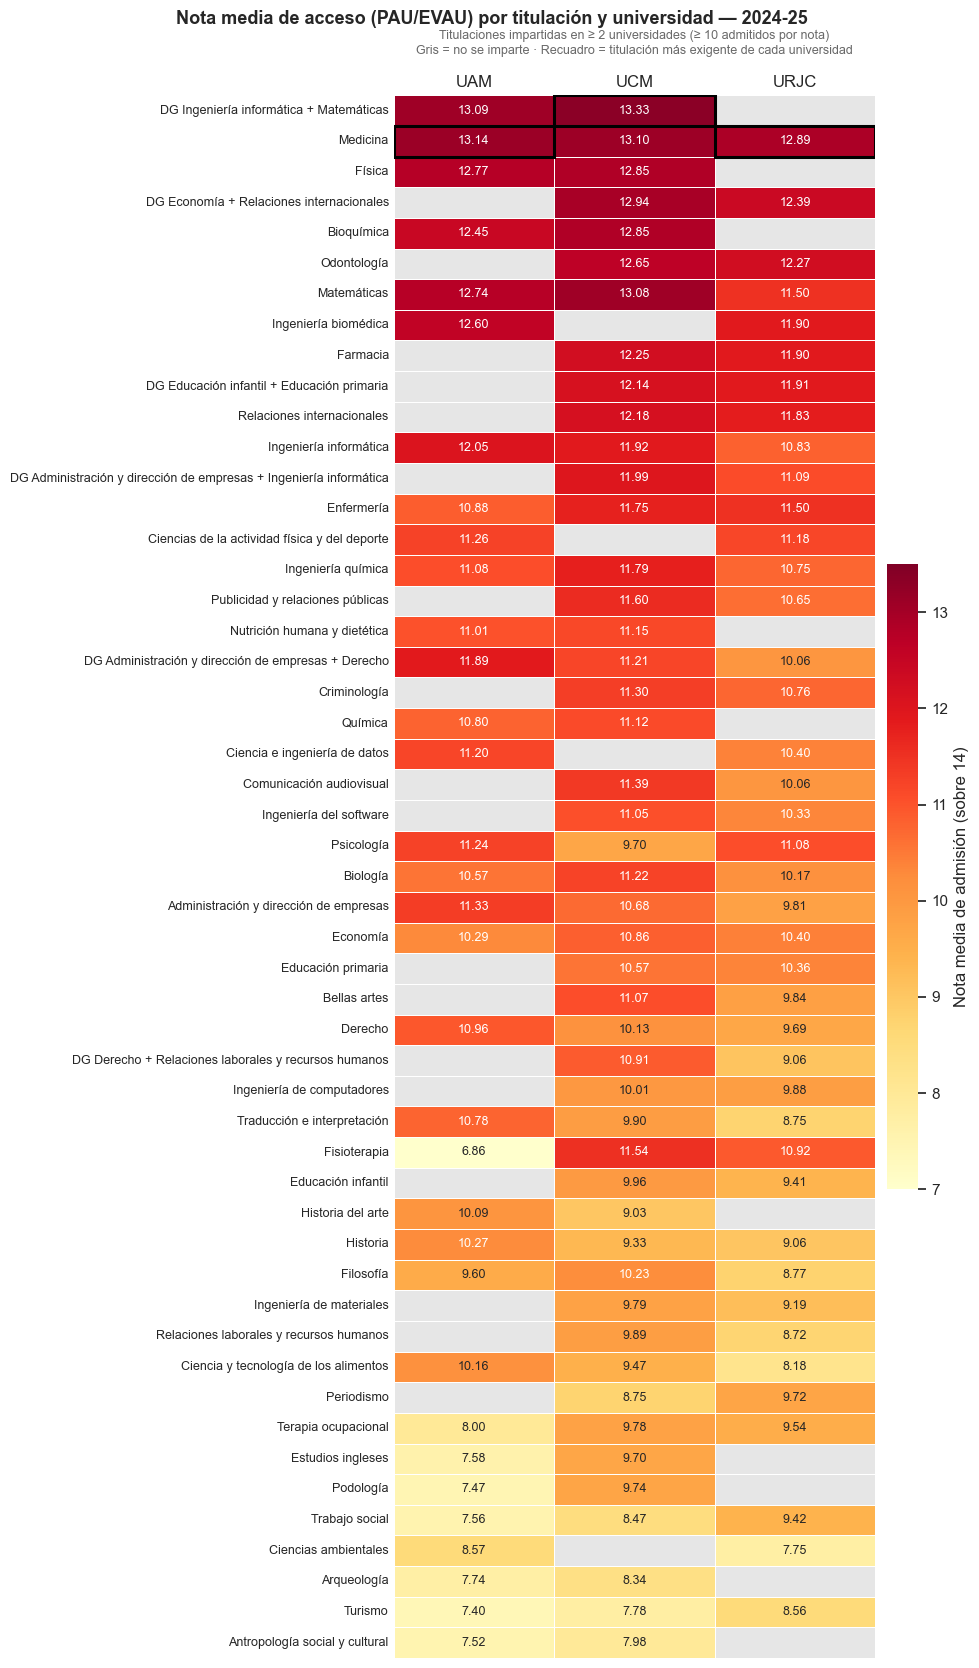

In [11]:
import re
import unicodedata

def sin_tildes(s):
    return unicodedata.normalize('NFKD', s).encode('ascii', 'ignore').decode()

def limpiar(titulacion):
    """Minúsculas y sin prefijos/sufijos administrativos (conserva las tildes)."""
    s = titulacion.lower()
    s = re.sub(r'\s*por la universidad.*$', '', s)
    s = re.sub(r'\(.*?\)', '', s)                                       # campus, plan...
    s = re.sub(r'\b(centro cardenal cisneros|instituto .*|c\.don bosco)$', '', s.strip())
    s = re.sub(r'maestro/a|maestro en|maestro', '', s)
    s = re.sub(r'graduado o graduada en|doble grado en|doble grado|grado en|grado', '', s)
    return re.sub(r'\s+', ' ', s).strip()

def partes_titulacion(s, simples):
    """Separa los dobles grados en sus dos titulaciones.
    UAM/UCM usan '-' o '/'; la URJC usa 'X y Y', así que solo se corta por ' y '/' e '
    cuando las dos mitades son titulaciones simples conocidas."""
    partes = [p.strip() for p in re.split(r'\s*[-/]\s*', s) if p.strip()]
    if len(partes) == 1:
        for m in re.finditer(r' (y|e) ', s):
            izq, der = s[:m.start()].strip(), s[m.end():].strip()
            if sin_tildes(izq) in simples and sin_tildes(der) in simples:
                return [izq, der]
    return partes

# Clave común (sin tildes, partes en orden alfabético) y etiqueta legible (con tildes)
limpias = notas['des_titulacion'].map(limpiar)
simples = set(limpias[~limpias.str.contains(r'[-/]')].map(sin_tildes))
partes = limpias.map(lambda s: sorted(partes_titulacion(s, simples), key=sin_tildes))
notas['titulacion'] = partes.map(lambda p: ' / '.join(sin_tildes(x) for x in p))
notas['etiqueta'] = partes.map(lambda p: ('DG ' if len(p) > 1 else '') + ' + '.join(x.capitalize() for x in p))

# La URJC escribe sin tildes: para cada titulación se usa la etiqueta con más tildes
etiquetas = (notas.drop_duplicates('etiqueta')
                  .assign(tildes=lambda d: d['etiqueta'].map(lambda e: len(e) - len(sin_tildes(e))))
                  .sort_values('tildes').groupby('titulacion')['etiqueta'].last())

# Nota media por titulación y universidad (≥ 10 admitidos por nota para que la media sea fiable)
MIN_ADMITIDOS = 10
medias = (notas.groupby(['titulacion', 'universidad'])['nota_admision']
               .agg(n='size', nota_media='mean').reset_index())
medias = medias[medias['n'] >= MIN_ADMITIDOS]

tabla = medias.pivot(index='titulacion', columns='universidad', values='nota_media')[orden_unis]
tabla = tabla[tabla.notna().sum(axis=1) >= 2]                   # solo las comparables
tabla = tabla.loc[tabla.mean(axis=1).sort_values(ascending=False).index]
tabla.index = tabla.index.map(etiquetas)

fig, ax = plt.subplots(figsize=(10, 17))
ax.set_facecolor('#e6e6e6')                                     # celdas vacías = no se imparte
ax.grid(False)

sb.heatmap(
    tabla, annot=True, fmt='.2f', cmap='YlOrRd', vmin=7, vmax=13.5,
    linewidths=0.6, linecolor='white', annot_kws={'fontsize': 9},
    cbar_kws={'label': 'Nota media de admisión (sobre 14)', 'shrink': 0.4, 'pad': 0.02},
    ax=ax,
)

# Recuadro en la titulación más exigente de cada universidad
for j, uni in enumerate(orden_unis):
    i = tabla.index.get_loc(tabla[uni].idxmax())
    ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=False, edgecolor='black', lw=2.2))

ax.set_xlabel('')
ax.set_ylabel('')
ax.xaxis.tick_top()
ax.tick_params(axis='x', labelsize=12, length=0)
ax.tick_params(axis='y', labelsize=9, length=0)
fig.suptitle('Nota media de acceso (PAU/EVAU) por titulación y universidad — 2024-25',
             fontsize=13, fontweight='bold')
ax.set_title(f'Titulaciones impartidas en ≥ 2 universidades (≥ {MIN_ADMITIDOS} admitidos por nota)\n'
             'Gris = no se imparte · Recuadro = titulación más exigente de cada universidad',
             fontsize=9, color='dimgray', pad=30)

fig.tight_layout()
plt.show()